# code_215 · A use record must bind evidence, limits and decision owners

**Book:** section 40.5. Restart and run all cells. Imports, helpers and generated observations are internal; ordinary execution is offline and CPU-only, with no credentials or files. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_40_GUIDE.md), [execution evidence](../CHAPTER_40_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_215).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0 and scikit-learn 1.9.0. Allow two minutes to execute and 45–90 minutes to interpret. Evidence contracts identify the protected unit, group denominators, permitted access, threat assumptions and decision responsibility. All household identities and data are generated fixtures. Seeded privacy-noise simulations are reproducible utility demonstrations, not protected releases. Original experiments expose metric behaviour; they are not benchmark reproductions or evidence that the generated law describes inspected structures. Simulator-only truth is labelled separately from observable assessment. No final score chooses a model or threshold. No dependency or asset is added.


In [1]:
import platform,time,json,copy
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from scipy.special import expit
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=8015;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print(platform.system(),platform.machine(),'CPU; seed',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
Darwin arm64 CPU; seed 8015


## Bind a model to a specific intended use and evidence record
 Fit a generated source logistic model on1,000 candidates and assess500 independent final candidates, with no threshold tuning. Its output supports review prioritization only; it is not a structural clearance. Construct a model-card-like record containing version, model digest, target event, data provenance, measured Brier/error, information boundaries, intended and excluded uses, subgroup-evidence limitation, privacy/security limits, decision-owner role and incident route. Required-field validation checks completeness, not truth or adequacy. A deliberately missing owner must fail. The people and role assignments below are fictional scenario fixtures; no real owner approval is claimed. Complete documentation does not replace independent evidence, accountable review or legal analysis.


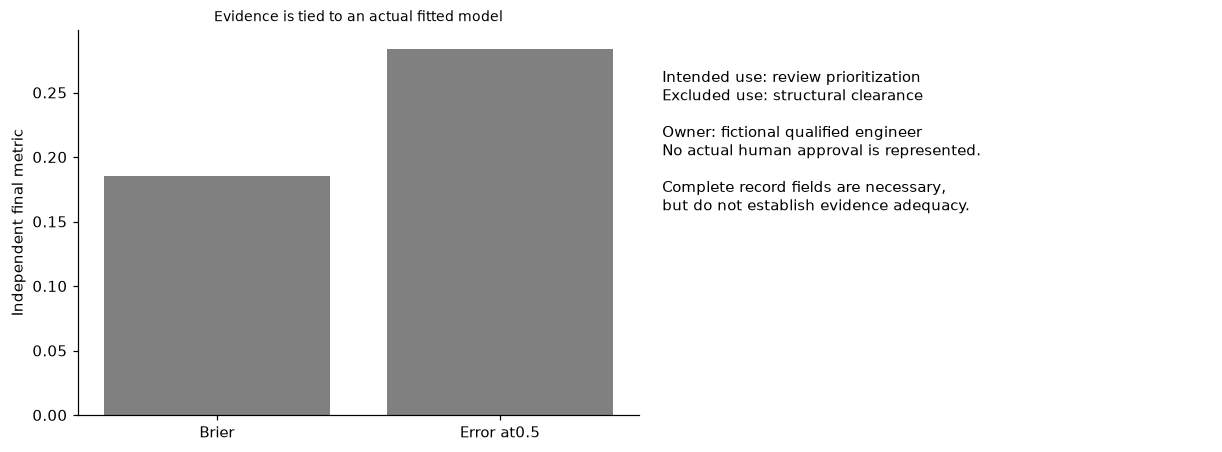

In [2]:
import hashlib
from sklearn.linear_model import LogisticRegression
xs=rng.normal(size=(1000,3));ys=rng.binomial(1,expit(-.5+xs@np.array([1.,-.6,.4])));xf=rng.normal(size=(500,3));yf=rng.binomial(1,expit(-.5+xf@np.array([1.,-.6,.4])));model=LogisticRegression(max_iter=300).fit(xs,ys);pf=model.predict_proba(xf)[:,1];metrics={'Brier':float(np.mean((pf-yf)**2)),'error':float(np.mean((pf>=.5)!=yf)),'final_n':500};model_digest=hashlib.sha256(model.coef_.tobytes()+model.intercept_.tobytes()).hexdigest();record={'model_id':'fictional-review-model','version':'1.0-fixture','model_digest':model_digest,'target_event':'generated actionable inspection finding','intended_use':'review_prioritization','excluded_use':'structural_clearance','data_provenance':'locally generated fictional candidates; no real household data','evidence':metrics,'information_boundary':'source fit; independent frozen final assessment','group_evidence':'not established by this small lifecycle fixture; see separate group audit','privacy_limit':'no private data; no DP trained model claim','security_limit':'in-memory test; no production IAM or supply-chain validation','decision_owner_role':'fictional qualified structural engineer','incident_route':'suspend review support and route to fictional service owner','review_date':'2026-10-22'};required=set(record)
def validate(card):
    missing=required-set(card)
    if missing or any(card[k] is None or card[k]=='' for k in required):raise ValueError('Missing evidence/use fields')
    if card['model_digest']!=model_digest:raise ValueError('Evidence is for another model')
    return True
assert validate(record);bad=record.copy();bad.pop('decision_owner_role');missing_rejected=False
try:validate(bad)
except ValueError:missing_rejected=True
assert missing_rejected;assert metrics['Brier']<.25;RESULTS.update(source_candidates=1000,independent_final_metrics=metrics,use_record=record,required_fields=len(required),missing_owner_rejected=True,record_completeness_is_not_validity=True,real_human_approval_claimed=False);fig,axes=plt.subplots(1,2,figsize=(11,4));axes[0].bar([0,1],[metrics['Brier'],metrics['error']],color='.5');axes[0].set(xticks=[0,1],xticklabels=['Brier','Error at0.5'],ylabel='Independent final metric',title='Evidence is tied to an actual fitted model');axes[1].axis('off');axes[1].text(.02,.9,'Intended use: review prioritization\nExcluded use: structural clearance\n\nOwner: fictional qualified engineer\nNo actual human approval is represented.\n\nComplete record fields are necessary,\nbut do not establish evidence adequacy.',va='top',fontsize=10);plt.show()


## Enforce a simulated workflow and preserve incident history
 The allowed state sequence is draft→verified→review_ready→suspended→retired. A fictional release_officer may move verified evidence into review_ready; this is scenario logic, not actual authorization. Requests are admitted only in review_ready and only for review_prioritization. An excluded structural-clearance request is rejected; after a recorded unit-metadata incident, even review support is suspended. Retirement prevents reopening this version. Append each transition and request outcome to a canonical SHA256 hash chain, verify all links, and detect a modified historical payload. The unkeyed chain detects changes only against a retained trusted head: an attacker able to rewrite every link and head can forge a new chain. Real authentication, access controls and external evidence retention remain separate requirements. No automatic action judges a structure safe.


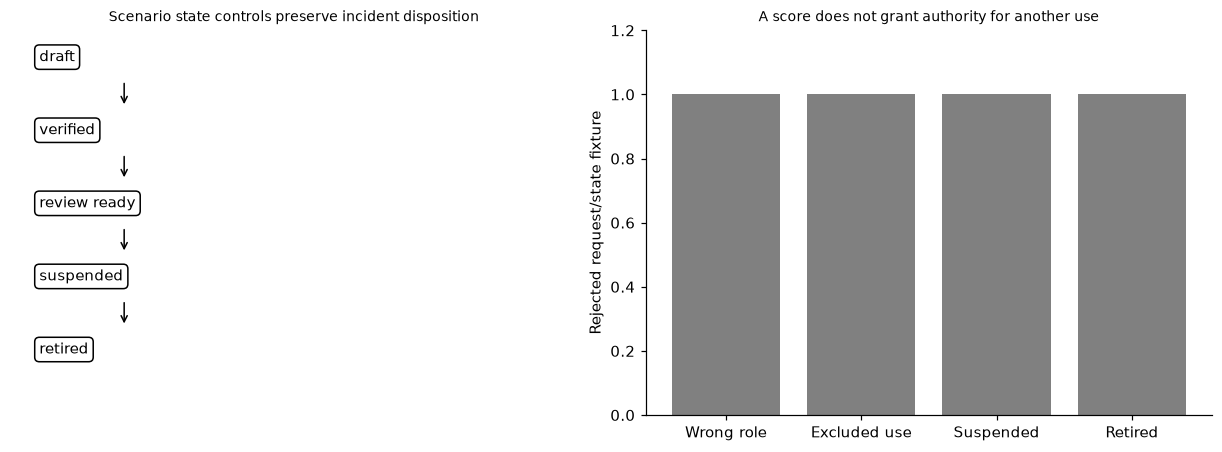

In [3]:
state='draft';events=[]
def append(kind,payload):
    previous=events[-1]['digest'] if events else 'GENESIS';entry={'sequence':len(events),'kind':kind,'payload':payload,'previous':previous};entry['digest']=hashlib.sha256(json.dumps(entry,sort_keys=True,separators=(',',':')).encode()).hexdigest();events.append(entry)
def verify(log):
    previous='GENESIS'
    for sequence,entry in enumerate(log):
        body={k:v for k,v in entry.items() if k!='digest'}
        if body['sequence']!=sequence or body['previous']!=previous or hashlib.sha256(json.dumps(body,sort_keys=True,separators=(',',':')).encode()).hexdigest()!=entry['digest']:return False
        previous=entry['digest']
    return True
def transition(new,role):
    global state
    allowed={('draft','verified'):'evidence_reviewer',('verified','review_ready'):'release_officer',('review_ready','suspended'):'incident_owner',('suspended','retired'):'service_owner'}
    if allowed.get((state,new))!=role:raise PermissionError('Invalid scenario state or role')
    append('transition',{'from':state,'to':new,'fictional_role':role,'model_digest':model_digest});state=new
def request(use):
    allowed=state=='review_ready' and use==record['intended_use'];append('request',{'use':use,'state':state,'admitted':allowed});return allowed
transition('verified','evidence_reviewer');wrong_role=False
try:transition('review_ready','analyst')
except PermissionError:wrong_role=True
assert wrong_role;transition('review_ready','release_officer');assert request('review_prioritization');assert not request('structural_clearance');append('incident',{'finding':'unrecognized unit metadata','action':'suspend support pending independent investigation'});transition('suspended','incident_owner');assert not request('review_prioritization');transition('retired','service_owner');assert not request('review_prioritization');assert verify(events);tampered=copy.deepcopy(events);tampered[0]['payload']['to']='review_ready';assert not verify(tampered);retired_reopen=False
try:transition('review_ready','release_officer')
except PermissionError:retired_reopen=True
assert retired_reopen;RESULTS.update(lifecycle_event_count=len(events),final_state=state,wrong_role_rejected=True,excluded_clearance_rejected=True,suspended_review_rejected=True,retired_reopen_rejected=True,audit_chain_valid=True,historical_payload_change_detected=True,unkeyed_chain_is_not_authentication=True,simulated_roles_are_not_real_approval=True,audit_head=events[-1]['digest']);fig,axes=plt.subplots(1,2,figsize=(11,4));axes[0].axis('off')
for i,label in enumerate(['draft','verified','review ready','suspended','retired']):
    axes[0].text(.05,.92-i*.19,label,bbox={'boxstyle':'round','facecolor':'white','edgecolor':'black'},fontsize=10)
    if i<4:axes[0].annotate('',xy=(.2,.80-i*.19),xytext=(.2,.87-i*.19),arrowprops={'arrowstyle':'->'})
axes[0].set_title('Scenario state controls preserve incident disposition');axes[1].bar(range(4),[1,1,1,1],color='.5');axes[1].set(xticks=range(4),xticklabels=['Wrong role','Excluded use','Suspended','Retired'],ylabel='Rejected request/state fixture',ylim=(0,1.2),title='A score does not grant authority for another use');plt.show()


In [4]:
summary={'example_id':'code_215','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual fitted model metrics bound to an executable evidence/use record', 'simulated role intended-use and lifecycle state gates', 'canonical hash-chain audit log with change detection and authenticity limits', 'incident suspension and retirement preserve evidence without autonomous structural clearance'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual fitted model metrics bound to an executable evidence/use record", "simulated role intended-use and lifecycle state gates", "canonical hash-chain audit log with change detection and authenticity limits", "incident suspension and retirement preserve evidence without autonomous structural clearance"], "elapsed_seconds": 0.248, "example_id": "code_215", "hardware": "Darwin arm64 CPU", "results": {"audit_chain_valid": true, "audit_head": "ef1e50b9f73bf90571e3b915d42743817e219e7bc1de6ac553712e6b947d6c64", "excluded_clearance_rejected": true, "final_state": "retired", "historical_payload_change_detected": true, "independent_final_metrics": {"Brier": 0.18543470961942962, "error": 0.284, "final_n": 500}, "lifecycle_event_count": 9, "missing_owner_rejected": true, "real_human_approval_claimed": false, "record_completeness_is_not_validity": true, "required_fields": 15, "retired_reopen_rejected": true, "simulated_roles_are_not_real_approval